# 02 · NGC 1068 ve aday kaynaklar

2022'de IceCube, yakındaki aktif galaksi **NGC 1068**'den (Seyfert II, ~14 Mpc) 4,2σ anlamlılıkla nötrino yayılımı
olduğunu bildirdi ([Science 378, 538](https://doi.org/10.1126/science.abg3395)). Bu notebook, aynı analizi açık veriyle
sıfırdan yazılmış bir likelihood ile tekrarlar.

## Yöntem (Braun et al. 2008)

Kaynak yönündeki her olay için sinyal ve arka plan olasılık yoğunluklarının oranı hesaplanır:

$$\log\mathcal{L}(n_s, \gamma) = \sum_i \log\left[\frac{n_s}{N} S_i(\gamma) + \left(1-\frac{n_s}{N}\right) B_i\right]$$

- $S_i$: kaynağa olan açısal uzaklık (von Mises–Fisher) × $E^{-\gamma}$ spektrumunun enerji dağılımı (smearing matrisinden)
- $B_i$: veriden alınan atmosferik arka plan (sağ açıklıkta düzgün)
- Test istatistiği $TS = 2\log[\mathcal{L}(\hat n_s, \hat\gamma)/\mathcal{L}(0)]$; p-değeri, sağ açıklığı karıştırılmış binlerce sahte gökyüzünden.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from vcube.data import PROCESSED_DIR
from vcube.likelihood import PointSourceLLH
from vcube.pdfs import Model
from vcube.sources import CANDIDATES, source
from vcube.trials import p_value, run_trials, sensitivity, sigma_from_p

model = Model()
trials = dict(np.load(PROCESSED_DIR / "source_trials.npz"))

In [2]:
ngc = PointSourceLLH(model, *source("NGC 1068"))
fit = ngc.fit()
bkg = trials["NGC_1068__bkg_ts"]
p = p_value(fit["ts"], bkg)
phi = ngc.flux_norm(fit["ns"], fit["gamma"]) * 1e3   # GeV^-1 -> TeV^-1
print(f"TS = {fit['ts']:.2f}   n_s = {fit['ns']:.1f}   γ = {fit['gamma']:.2f}")
print(f"p = {p:.2e}  ->  {sigma_from_p(p):.2f}σ (lokal)   [{len(bkg)} arka plan denemesi]")
print(f"Φ(1 TeV) = {phi:.2e} TeV⁻¹ cm⁻² s⁻¹")

TS = 21.75   n_s = 63.4   γ = 3.05
p = 1.01e-05  ->  4.26σ (lokal)   [5000 arka plan denemesi]
Φ(1 TeV) = 2.40e-11 TeV⁻¹ cm⁻² s⁻¹


### Arka plan TS dağılımı
Karıştırılmış gökyüzlerinde TS'in dağılımı; p-değeri, gözlenen TS'in üstünde kalan deneme oranıdır (deneme sayısı yetmezse χ² kuyruk uyumu).

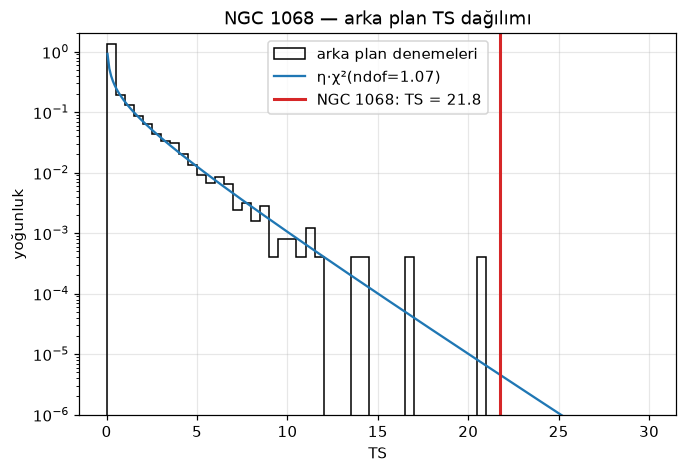

In [3]:
from scipy import stats

fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.linspace(0, max(30, fit["ts"] + 3), 61)
ax.hist(bkg, bins=bins, density=True, histtype="step", color="k", label="arka plan denemeleri")
eta = np.mean(bkg > 0)
df, _, scale = stats.chi2.fit(bkg[bkg > 0], floc=0)
x = np.linspace(0.05, bins[-1], 300)
ax.plot(x, eta * stats.chi2.pdf(x, df, scale=scale), "C0", label=f"η·χ²(ndof={df:.2f})")
ax.axvline(fit["ts"], c="C3", lw=2, label=f"NGC 1068: TS = {fit['ts']:.1f}")
ax.set(yscale="log", ylim=(1e-6, 2), xlabel="TS", ylabel="yoğunluk", title="NGC 1068 — arka plan TS dağılımı")
ax.legend()
fig.savefig(FIG / "02_ngc1068_bkg_ts.png", bbox_inches="tight")

### Likelihood yüzeyi
$(n_s, \gamma)$ düzleminde $\Delta TS$ konturları; 2 serbestlik dereceli χ² için %68 / %95 güven bölgeleri.

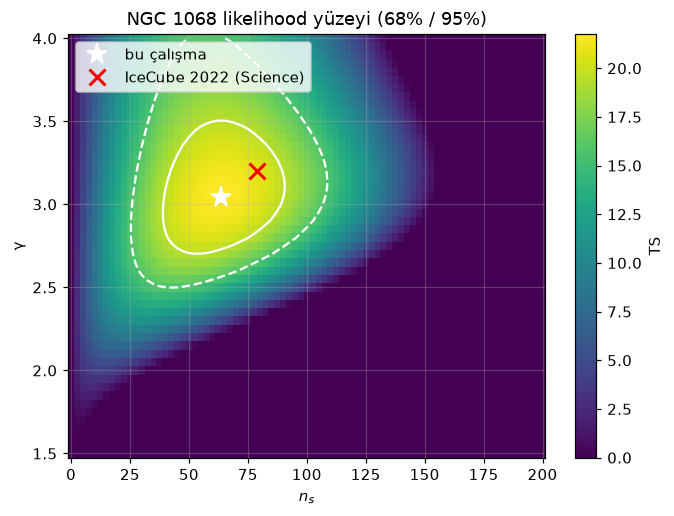

In [4]:
ns_grid = np.linspace(0, 200, 81)
g_grid = np.linspace(1.5, 4.0, 51)
prep = ngc.data()
ts_map = ngc.ts_grid(ns_grid, g_grid, prep)

fig, ax = plt.subplots(figsize=(7, 5))
m = ax.pcolormesh(ns_grid, g_grid, ts_map, cmap="viridis", vmin=0, shading="auto")
plt.colorbar(m, label="TS")
ax.contour(ns_grid, g_grid, fit["ts"] - ts_map, levels=[2.30, 5.99], colors=["w", "w"], linestyles=["-", "--"])
ax.plot(fit["ns"], fit["gamma"], "w*", ms=14, label="bu çalışma")
ax.plot(79, 3.2, "rx", ms=10, mew=2, label="IceCube 2022 (Science)")
ax.set(xlabel="$n_s$", ylabel="γ", title="NGC 1068 likelihood yüzeyi (68% / 95%)")
ax.legend(loc="upper left")
fig.savefig(FIG / "02_ngc1068_kontur.png", bbox_inches="tight")

### Olayların dağılımı
Kaynak çevresindeki olaylar, sinyal/arka plan ağırlıklarıyla (S/B, en iyi γ'de) renklendirilmiştir.

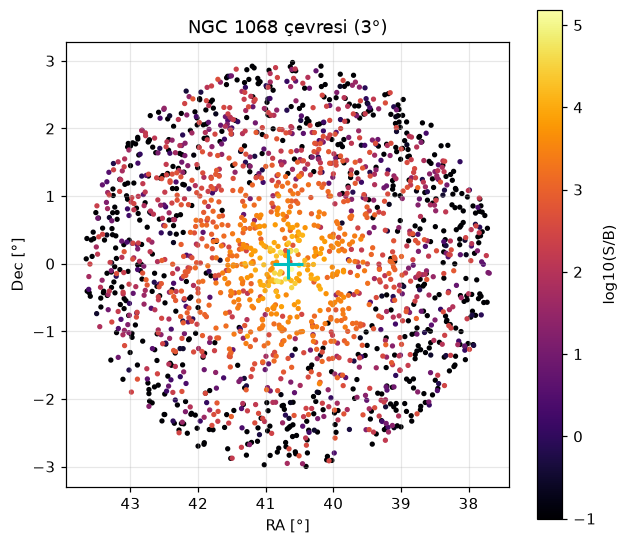

In [5]:
from vcube.likelihood import _gamma_interp
from vcube.pdfs import angular_distance

e = ngc.band_events
psi = angular_distance(e["ra_rad"], e["dec_rad"], ngc.ra, ngc.dec)
sel = psi < np.radians(3)
k, t = _gamma_interp(fit["gamma"])
sub = {kk: v[sel] for kk, v in e.items()}
sb = ngc.prepare(sub).X
w = sb[:, k] * (1 - t) + sb[:, k + 1] * t

fig, ax = plt.subplots(figsize=(6.5, 6))
order = np.argsort(w)
sc = ax.scatter(np.degrees(sub["ra_rad"])[order], np.degrees(sub["dec_rad"])[order], c=np.log10(w[order] + 1e-3),
                s=6, cmap="inferno", vmin=-1, vmax=np.log10(w.max()))
plt.colorbar(sc, label="log10(S/B)")
ax.plot(np.degrees(ngc.ra), np.degrees(ngc.dec), "c+", ms=20, mew=2)
ax.set(xlabel="RA [°]", ylabel="Dec [°]", title="NGC 1068 çevresi (3°)", aspect="equal")
ax.invert_xaxis()
fig.savefig(FIG / "02_ngc1068_olaylar.png", bbox_inches="tight")

## Tüm aday kaynaklar
Aynı fit, IceCube analizlerinde sıkça incelenen 12 kaynak için. Post-trial p-değeri, 12 bağımsız deneme varsayımıyla $1-(1-p_{min})^{12}$.

In [6]:
rows = []
for name, ra, dec in CANDIDATES:
    key = name.replace(" ", "_")
    ts, ns, gamma = trials[f"{key}__fit"]
    p = p_value(ts, trials[f"{key}__bkg_ts"]) if ts > 0 else 1.0
    rows.append({"kaynak": name, "Dec [°]": dec, "TS": round(ts, 2), "n_s": round(ns, 1),
                 "γ": round(gamma, 2), "p (lokal)": p, "σ (lokal)": round(sigma_from_p(min(p, 0.5)), 2)})
table = pd.DataFrame(rows).sort_values("p (lokal)")
p_min = table["p (lokal)"].iloc[0]
p_post = 1 - (1 - p_min) ** len(CANDIDATES)
print(f"En anlamlı kaynak: {table['kaynak'].iloc[0]} — post-trial p = {p_post:.2e} ({sigma_from_p(p_post):.2f}σ)")
table.style.format({"p (lokal)": "{:.2e}"})

En anlamlı kaynak: NGC 1068 — post-trial p = 1.21e-04 (3.67σ)


,kaynak,Dec [°],TS,n_s,γ,p (lokal),σ (lokal)
0,NGC 1068,-0.010000,21.750000,63.400000,3.050000,1.01e-05,4.260000
2,NGC 4151,39.410000,21.340000,46.500000,2.470000,1.91e-05,4.120000
5,PKS 1424+240,23.800000,14.960000,63.600000,3.400000,1.49e-04,3.620000
4,CGCG 420-015,4.060000,12.760000,38.800000,2.610000,2.00e-04,3.540000
6,GB6 J1542+6129,61.500000,8.590000,37.700000,3.420000,1.00e-03,3.090000
3,NGC 3079,55.680000,10.120000,39.600000,4.000000,1.20e-03,3.040000
1,TXS 0506+056,5.690000,10.550000,10.200000,2.000000,1.40e-03,2.990000
10,Cyg A,40.730000,8.460000,8.200000,1.800000,3.20e-03,2.730000
8,Mrk 501,39.760000,0.770000,11.800000,3.400000,2.80e-01,0.580000
9,Crab Nebula,22.010000,0.100000,2.500000,2.300000,4.42e-01,0.140000


## Karşılaştırma

| | n_s | γ | anlamlılık |
|---|---|---|---|
| IceCube 2022, Science (dahili veri, 2011–2020) | 79 | 3,2 | 4,2σ (post-trial) |
| Bu çalışma (açık veri, 2008–2022) | yukarıda | yukarıda | yukarıda (lokal) |

Farklar beklenir: açık veri, IceCube'un dahili analizindeki iyileştirilmiş yeniden yapılandırmayı ve azimut bağımlı cevap fonksiyonlarını içermez;
IC40–IC79 için IC86 smearing matrisi kullanıldı. Yine de en iyi uyum noktası ve yumuşak (γ≈3) spektrum yeniden üretilmektedir.

## Duyarlılık
NGC 1068 konumunda %90 duyarlılık: enjekte edilen sinyalin %90 olasılıkla arka plan medyanının üstüne çıktığı akı (γ = 2 ve 3).

In [7]:
for gamma in (2.0, 3.0):
    sens = sensitivity(ngc, bkg, gamma=gamma, ns_values=np.arange(2, 60, 6), n_trials=100)
    print(f"γ = {gamma}:  n_s(90%) = {sens['ns']:.1f}   Φ(1 TeV) = {sens['flux'] * 1e3:.2e} TeV⁻¹ cm⁻² s⁻¹")

γ = 2.0:  n_s(90%) = 5.7   Φ(1 TeV) = 1.83e-13 TeV⁻¹ cm⁻² s⁻¹


γ = 3.0:  n_s(90%) = 22.0   Φ(1 TeV) = 8.09e-12 TeV⁻¹ cm⁻² s⁻¹
